In [1]:
!mamba install pandas


mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 5.114 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [2]:
!mamba install pandas seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 4.061 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ pandas        3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ six           1.17.0   pyhe01879c_1         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x
- pip           26.2.2   pyh145f28c_0         conda-forge


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("student_tea_snacks.csv")  # update path if needed
print("Columns:", df.columns.tolist())
display(df.head())

Columns: ['student_id', 'gender', 'age_group', 'prefers_tea', 'tea_type', 'snack_choice', 'cups_per_day']


,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


#Q1 Most preferred tea type

In [5]:
popular_tea = df["tea_type"].mode()[0]
print(f"The most preferred tea type is: {popular_tea}")
print(df["tea_type"].value_counts(dropna=False))

The most preferred tea type is: Green
tea_type
Green          29
Doodh Patti    25
Black          23
NaN            23
Name: count, dtype: int64


#Q2 What is the average number of cups per gender?

In [6]:
avg_cups_gender = df.groupby("gender")["cups_per_day"].mean()
display(avg_cups_gender)


gender
Female    2.595745
Male      3.000000
Name: cups_per_day, dtype: float64

#Q3: Make a bar chart of snack choices.

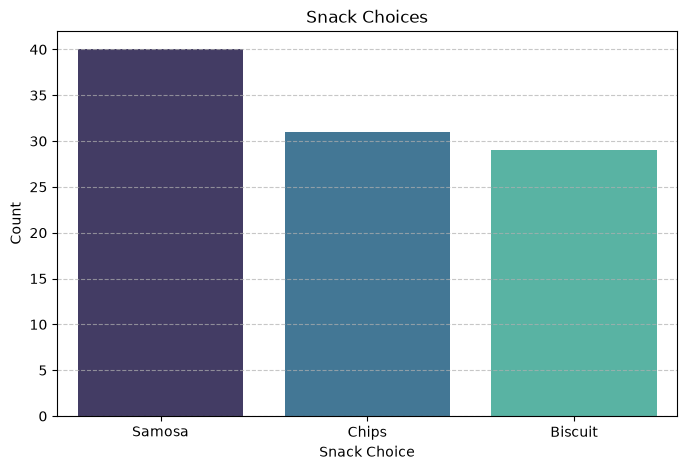

In [7]:
snack_counts = df["snack_choice"].value_counts().reset_index()
snack_counts.columns = ["snack_choice", "count"]

plt.figure(figsize=(8, 5))
sns.barplot(
    data=snack_counts,
    x="snack_choice",
    y="count",
    hue="snack_choice",
    palette="mako",
    legend=False,
)
plt.title("Snack Choices")
plt.xlabel("Snack Choice")
plt.ylabel("Count")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

#Q4: Compare tea preference by age group.

In [8]:
tea_by_age = pd.crosstab(df["age_group"], df["tea_type"])
display(tea_by_age)

# Optional: also compare 'prefers_tea' ('Yes' vs 'No') across age groups
display(pd.crosstab(df["age_group"], df["prefers_tea"]))

tea_type,Black,Doodh Patti,Green
age_group,,,
18-20,9,11,13
21-23,9,6,5
24-26,5,8,11


prefers_tea,No,Yes
age_group,,
18-20,19,20
21-23,17,15
24-26,13,16


#Q5: Count the number of students who don't drink tea.

In [9]:
no_tea_pref = (df["prefers_tea"] == "No").sum()
zero_cups = (df["cups_per_day"] == 0).sum()

print(f"Students with prefers_tea == 'No': {no_tea_pref}")
print(f"Students with cups_per_day == 0: {zero_cups}")

Students with prefers_tea == 'No': 49
Students with cups_per_day == 0: 13
